### Import Library

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from collections import defaultdict

### Load Dataset dan Kamus Inset

In [2]:
POS_LEXICON_PATH = '../../data/kamus/kamus_positive.xlsx'
NEG_LEXICON_PATH = '../../data/kamus/kamus_negative.xlsx'

TEXT_COL = "clean_text"

df = pd.read_csv('../../data/preprocessing/hasil_preprocessing.csv')

print("Jumlah data:", len(df))
print("Kolom dataset:", df.columns.tolist())

# Memastikan kolom clean_text ada
if TEXT_COL not in df.columns:
    raise ValueError(f"Kolom '{TEXT_COL}' tidak ditemukan di dataset.")

df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)

Jumlah data: 48546
Kolom dataset: ['text', 'original_text', 'clean_text']


### Function untuk Membaca Kamus

In [3]:
def load_lexicon(path, sentiment_type):
    """
    Membaca kamus Excel dengan kolom:
    - word
    - weight
    
    sentiment_type:
    - "positive"
    - "negative"
    """
    lex_df = pd.read_excel(path)

    # Normalisasi nama kolom
    lex_df.columns = [str(c).strip().lower() for c in lex_df.columns]

    if "word" not in lex_df.columns or "weight" not in lex_df.columns:
        raise ValueError(f"File {path} harus memiliki kolom 'word' dan 'weight'.")

    lex_df = lex_df[["word", "weight"]].dropna()
    lex_df["word"] = lex_df["word"].astype(str).str.lower().str.strip()
    lex_df["word"] = lex_df["word"].apply(lambda x: re.sub(r"\s+", " ", x))

    # Pastikan weight numerik
    lex_df["weight"] = pd.to_numeric(lex_df["weight"], errors="coerce")
    lex_df = lex_df.dropna(subset=["weight"])

    lexicon = {}

    for _, row in lex_df.iterrows():
        word = row["word"]
        weight = row["weight"]

        if sentiment_type == "positive":
            weight = abs(weight)
        elif sentiment_type == "negative":
            weight = -abs(weight)

        lexicon[word] = weight

    return lexicon


positive_lexicon = load_lexicon(POS_LEXICON_PATH, "positive")
negative_lexicon = load_lexicon(NEG_LEXICON_PATH, "negative")

print("Jumlah kata positif:", len(positive_lexicon))
print("Jumlah kata negatif:", len(negative_lexicon))

Jumlah kata positif: 3632
Jumlah kata negatif: 6682


### Gabungan Kamus dan Handle Konfli 

In [4]:
def merge_lexicons(pos_lexicon, neg_lexicon):
    """
    Jika ada kata yang muncul di positif dan negatif:
    - pilih bobot dengan nilai absolut paling besar
    - jika sama kuat, kata dihapus agar tidak menimbulkan bias
    """
    combined = {}
    conflict_terms = []

    all_terms = set(pos_lexicon.keys()) | set(neg_lexicon.keys())

    for term in all_terms:
        pos_score = pos_lexicon.get(term)
        neg_score = neg_lexicon.get(term)

        if pos_score is not None and neg_score is not None:
            conflict_terms.append({
                "term": term,
                "positive_weight": pos_score,
                "negative_weight": neg_score
            })

            if abs(pos_score) > abs(neg_score):
                combined[term] = pos_score
            elif abs(neg_score) > abs(pos_score):
                combined[term] = neg_score
            else:
                # Jika sama kuat, abaikan
                continue

        elif pos_score is not None:
            combined[term] = pos_score

        elif neg_score is not None:
            combined[term] = neg_score

    conflict_df = pd.DataFrame(conflict_terms)
    return combined, conflict_df


lexicon, conflict_df = merge_lexicons(positive_lexicon, negative_lexicon)

print("Jumlah total kamus gabungan:", len(lexicon))
print("Jumlah kata/frasa konflik:", len(conflict_df))

# Simpan daftar konflik untuk dokumentasi skripsi
conflict_df.to_excel("konflik_kamus_positive_negative.xlsx", index=False)

Jumlah total kamus gabungan: 8964
Jumlah kata/frasa konflik: 1131


### Memisahkan Kamus Kata Tunggal dan Frasa

In [5]:
phrase_lexicon = {}
word_lexicon = {}

for term, weight in lexicon.items():
    if " " in term:
        phrase_lexicon[term] = weight
    else:
        word_lexicon[term] = weight

# Urutkan frasa dari yang paling panjang agar frasa seperti
# "tidak becus" dibaca dulu sebelum "becus"
phrase_lexicon = dict(
    sorted(
        phrase_lexicon.items(),
        key=lambda x: len(x[0].split()),
        reverse=True
    )
)

print("Jumlah frasa:", len(phrase_lexicon))
print("Jumlah kata tunggal:", len(word_lexicon))

Jumlah frasa: 748
Jumlah kata tunggal: 8216


### Daftar Negasi, Intensifier, dan Indikator Sarkasme

In [6]:
NEGATION_WORDS = {
    "tidak", "tak", "tdk",
    "gak", "ga", "nggak", "ngga", "enggak",
    "bukan", "jangan", "belum", "kurang"
}

INTENSIFIER_WORDS = {
    "sangat": 1.5,
    "banget": 1.5,
    "bgt": 1.5,
    "amat": 1.5,
    "terlalu": 1.3,
    "sekali": 1.4,
    "parah": 1.5,
    "tolol": 1.3,
    "goblok": 1.3
}

SARCASM_MARKERS = {
    "wkwk", "wkwwk", "wkwkwk",
    "haha", "hahaha",
    "hebat banget", "bagus banget",
    "mantap banget", "luar biasa",
    "tepuk tangan"
}

CONTRAST_WORDS = {
    "tapi", "tetapi", "namun", "padahal", "sedangkan"
}

In [7]:
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

### Fungsi labeling InSet Lexicon

In [8]:
def inset_labeling(
    text,
    phrase_lexicon,
    word_lexicon,
    pos_threshold=2,
    neg_threshold=-2,
    negation_window=3
):
    original_text = normalize_text(text)
    working_text = original_text

    total_score = 0
    matched_terms = []

    # =========================
    # 1. Deteksi frasa dulu
    # =========================
    for phrase, weight in phrase_lexicon.items():
        pattern = r"\b" + re.escape(phrase) + r"\b"

        if re.search(pattern, working_text):
            count = len(re.findall(pattern, working_text))
            phrase_score = weight * count

            total_score += phrase_score

            matched_terms.append({
                "term": phrase,
                "weight": weight,
                "count": count,
                "score": phrase_score,
                "type": "phrase"
            })

            # Hapus frasa agar tidak dihitung ulang sebagai kata tunggal
            working_text = re.sub(pattern, " ", working_text)
            working_text = re.sub(r"\s+", " ", working_text).strip()

    # =========================
    # 2. Tokenisasi kata
    # =========================
    tokens = working_text.split()

    for i, token in enumerate(tokens):
        if token not in word_lexicon:
            continue

        base_score = word_lexicon[token]
        final_score = base_score

        # =========================
        # 3. Cek negasi sebelum kata sentimen
        # =========================
        start_idx = max(0, i - negation_window)
        previous_words = tokens[start_idx:i]

        has_negation = any(w in NEGATION_WORDS for w in previous_words)

        if has_negation:
            # Jika positif terkena negasi, ubah jadi negatif
            if base_score > 0:
                final_score = -abs(base_score)

            # Jika negatif terkena negasi, jangan selalu jadi positif kuat
            # Lebih aman menjadi positif ringan
            elif base_score < 0:
                final_score = abs(base_score) * 0.5

        # =========================
        # 4. Cek intensifier
        # =========================
        intensifier_multiplier = 1

        for w in previous_words:
            if w in INTENSIFIER_WORDS:
                intensifier_multiplier = max(
                    intensifier_multiplier,
                    INTENSIFIER_WORDS[w]
                )

        final_score = final_score * intensifier_multiplier

        total_score += final_score

        matched_terms.append({
            "term": token,
            "weight": base_score,
            "count": 1,
            "score": final_score,
            "type": "word",
            "negated": has_negation,
            "intensifier": intensifier_multiplier
        })

    # =========================
    # 5. Aturan sarkasme sederhana
    # =========================
    sarcasm_detected = any(marker in original_text for marker in SARCASM_MARKERS)

    if sarcasm_detected and total_score > 0:
        # Jangan langsung ubah jadi negatif,
        # cukup kurangi skor positif agar tidak terlalu optimis
        total_score = total_score * 0.5

    # =========================
    # 6. Aturan kontras sederhana
    # =========================
    # Contoh: "bagus tapi rakyat susah"
    # Bagian setelah "tapi/namun" biasanya lebih kuat
    contrast_detected = any(w in original_text.split() for w in CONTRAST_WORDS)

    # =========================
    # 7. Penentuan label berdasarkan threshold
    # =========================
    if total_score >= pos_threshold:
        label = "positive"
    elif total_score <= neg_threshold:
        label = "negative"
    else:
        label = "neutral"

    return {
        "label": label,
        "score": total_score,
        "matched_terms": matched_terms,
        "sarcasm_detected": sarcasm_detected,
        "contrast_detected": contrast_detected
    }

### Menerapkan Ke Dataset

In [9]:
results = df[TEXT_COL].apply(
    lambda x: inset_labeling(
        x,
        phrase_lexicon=phrase_lexicon,
        word_lexicon=word_lexicon,
        pos_threshold=2,
        neg_threshold=-2,
        negation_window=3
    )
)

df["label_inset"] = results.apply(lambda x: x["label"])
df["score_inset"] = results.apply(lambda x: x["score"])
df["matched_terms"] = results.apply(lambda x: x["matched_terms"])
df["sarcasm_detected"] = results.apply(lambda x: x["sarcasm_detected"])
df["contrast_detected"] = results.apply(lambda x: x["contrast_detected"])

print(df["label_inset"].value_counts())

label_inset
negative    26871
positive    11452
neutral     10223
Name: count, dtype: int64


### Visualisasi Label

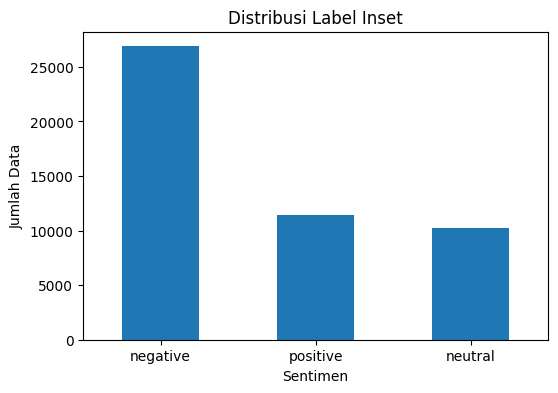

In [12]:
label_counts = df['label_inset'].value_counts()

plt.figure(figsize=(6,4))
label_counts.plot(kind='bar')
plt.title('Distribusi Label Inset')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)
plt.show()

### Menyimpan Hasil Labeling

In [ ]:
OUTPUT_PATH = "../../data/labeled/inset_labeling.csv"

df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8-sig")

print("File tersimpan:", OUTPUT_PATH)

File tersimpan: ../../data/labeled/inset_labeling.csv


In [14]:
df[[TEXT_COL, "label_inset", "score_inset", "matched_terms"]].sample(10, random_state=42)

,clean_text,label_inset,score_inset,matched_terms
7360,kamu punya agama,neutral,0.0,"[{'term': 'punya', 'weight': 3, 'count': 1, 's..."
31562,resmi republik dinasti besar se dunia kapan,neutral,1.0,"[{'term': 'resmi', 'weight': 2, 'count': 1, 's..."
35175,gila,negative,-4.0,"[{'term': 'gila', 'weight': -4, 'count': 1, 's..."
22358,harga pemgimpor sandang pangan besar broo,positive,7.0,"[{'term': 'harga', 'weight': 3, 'count': 1, 's..."
23875,b sih nih nemu vidieo lama nih waktu si anies ...,negative,-30.0,"[{'term': 'haus kuasa', 'weight': -5, 'count':..."
12635,kalau kata zulhas harga beras indonesia murah,positive,4.0,"[{'term': 'kalau', 'weight': -1, 'count': 1, '..."
22868,siap mantap pak jangan mpox rajalela indonesia...,neutral,1.0,"[{'term': 'siap', 'weight': 1, 'count': 1, 'sc..."
2116,psi tempat ngumpulnya islamphobiasekuleratheis...,negative,-5.0,"[{'term': 'tempat', 'weight': -3, 'count': 1, ..."
30423,beda konoha,negative,-2.0,"[{'term': 'beda', 'weight': -2, 'count': 1, 's..."
8305,kapan eling sadargak lama tahun smpeyan rusak ...,negative,-22.0,"[{'term': 'lama', 'weight': -4, 'count': 1, 's..."
